FIVE-YEAR OPERATING TABLE COST ANALYSIS


,Operating Table,Best Case Purchases,Worst Case Purchases,Best Case Purchase Cost,Worst Case Purchase Cost,Maintenance,Repairs,Downtime,Best Case TCO,Worst Case TCO,Best Case Ranking,Worst Case Ranking
0,Table A - Budget,2,3,"₦6,000,000","₦9,000,000","₦1,500,000","₦2,500,000","₦7,500,000","₦17,500,000","₦20,500,000",1,1
1,Table B - Premium,1,1,"₦19,000,000","₦19,000,000","₦1,250,000","₦1,000,000","₦3,000,000","₦24,250,000","₦24,250,000",2,2



BEST-CASE COST DIFFERENCE: ₦6,750,000
WORST-CASE COST DIFFERENCE: ₦3,750,000


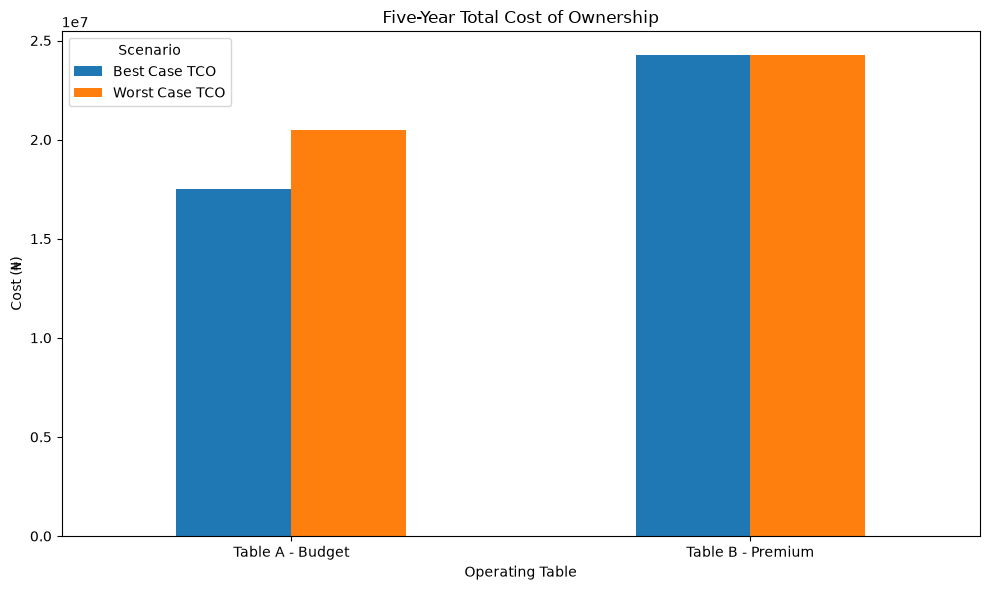

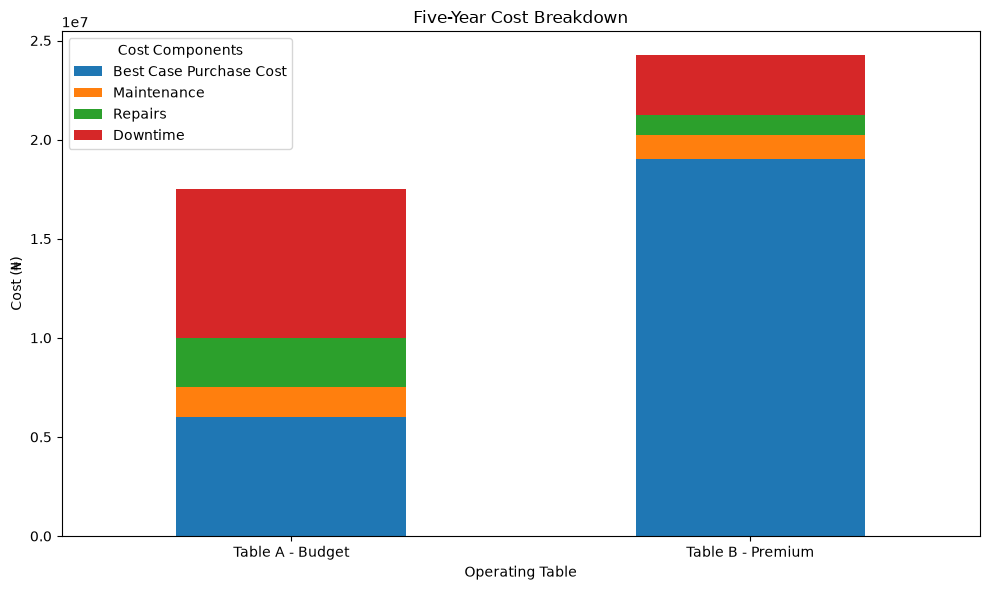


Analysis completed.


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ==========================================
# 1. PROJECT DATA AND ASSUMPTIONS
# ==========================================

tables = {
    "Table A - Budget": {
        "purchase_cost": 3_000_000,
        "min_lifespan": 2,
        "max_lifespan": 3,
        "annual_maintenance": 300_000,
        "annual_repairs": 500_000,
        "downtime_days": 5,
        "downtime_cost_per_day": 300_000
    },

    "Table B - Premium": {
        "purchase_cost": 19_000_000,
        "min_lifespan": 10,
        "max_lifespan": 15,
        "annual_maintenance": 250_000,
        "annual_repairs": 200_000,
        "downtime_days": 2,
        "downtime_cost_per_day": 300_000
    }
}

analysis_period = 5

# ==========================================
# 2. CALCULATE FIVE-YEAR COSTS
# ==========================================

results = []

for name, data in tables.items():

    # Number of purchases over five years
    best_case_purchases = (
        analysis_period + data["max_lifespan"] - 1
    ) // data["max_lifespan"]

    worst_case_purchases = (
        analysis_period + data["min_lifespan"] - 1
    ) // data["min_lifespan"]

    # Purchase and replacement expenditure
    best_purchase_cost = (
        best_case_purchases * data["purchase_cost"]
    )

    worst_purchase_cost = (
        worst_case_purchases * data["purchase_cost"]
    )

    # Maintenance and repair expenditure
    maintenance_cost = (
        data["annual_maintenance"] * analysis_period
    )

    repair_cost = (
        data["annual_repairs"] * analysis_period
    )

    # Downtime expenditure
    downtime_cost = (
        data["downtime_days"]
        * data["downtime_cost_per_day"]
        * analysis_period
    )

    # Total ownership costs
    best_tco = (
        best_purchase_cost
        + maintenance_cost
        + repair_cost
        + downtime_cost
    )

    worst_tco = (
        worst_purchase_cost
        + maintenance_cost
        + repair_cost
        + downtime_cost
    )

    results.append({
        "Operating Table": name,
        "Best Case Purchases": best_case_purchases,
        "Worst Case Purchases": worst_case_purchases,
        "Best Case Purchase Cost": best_purchase_cost,
        "Worst Case Purchase Cost": worst_purchase_cost,
        "Maintenance": maintenance_cost,
        "Repairs": repair_cost,
        "Downtime": downtime_cost,
        "Best Case TCO": best_tco,
        "Worst Case TCO": worst_tco
    })

# ==========================================
# 3. CREATE RESULTS TABLE
# ==========================================

df = pd.DataFrame(results)

df["Best Case Ranking"] = (
    df["Best Case TCO"]
    .rank(method="min")
    .astype(int)
)

df["Worst Case Ranking"] = (
    df["Worst Case TCO"]
    .rank(method="min")
    .astype(int)
)

print("FIVE-YEAR OPERATING TABLE COST ANALYSIS")

display(
    df.style.format({
        col: "₦{:,.0f}"
        for col in [
            "Best Case Purchase Cost",
            "Worst Case Purchase Cost",
            "Maintenance",
            "Repairs",
            "Downtime",
            "Best Case TCO",
            "Worst Case TCO"
        ]
    })
)

# ==========================================
# 4. COST DIFFERENCE
# ==========================================

best_difference = (
    df["Best Case TCO"].iloc[1]
    - df["Best Case TCO"].iloc[0]
)

worst_difference = (
    df["Worst Case TCO"].iloc[1]
    - df["Worst Case TCO"].iloc[0]
)

print("\nBEST-CASE COST DIFFERENCE: ₦{:,.0f}".format(
    best_difference
))

print("WORST-CASE COST DIFFERENCE: ₦{:,.0f}".format(
    worst_difference
))

# ==========================================
# 5. VISUALISATION: BEST VS WORST CASE
# ==========================================

plot_df = df.set_index("Operating Table")[
    ["Best Case TCO", "Worst Case TCO"]
]

plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Five-Year Total Cost of Ownership")
plt.ylabel("Cost (₦)")
plt.xlabel("Operating Table")
plt.xticks(rotation=0)
plt.legend(title="Scenario")
plt.tight_layout()
plt.show()

# ==========================================
# 6. VISUALISATION: COST COMPONENTS
# ==========================================

component_df = df.set_index("Operating Table")[
    [
        "Best Case Purchase Cost",
        "Maintenance",
        "Repairs",
        "Downtime"
    ]
]

component_df.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Five-Year Cost Breakdown")
plt.ylabel("Cost (₦)")
plt.xlabel("Operating Table")
plt.xticks(rotation=0)
plt.legend(title="Cost Components")
plt.tight_layout()
plt.show()

# ==========================================
# 7. EXPORT RESULTS
# ==========================================

df.to_csv(
    "operating_table_financial_analysis.csv",
    index=False
)

print("\nAnalysis completed.")

